In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"C:\Users\shrinivas\OneDrive\Documents\Loan_Default_Credit_Risk_Analysis\Cleaned_Data\credit_risk_cleaned.csv"
)

df.head()

Matplotlib is building the font cache; this may take a moment.


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22.0,59000,RENT,NaN,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21.0,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25.0,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23.0,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24.0,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [2]:
print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicates:", df.duplicated().sum())

print("\nLoan Status:")
print(df["loan_status"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Rows: 32416
Columns: 12
Duplicates: 0

Loan Status:
loan_status
0    25327
1     7089
Name: count, dtype: int64

Missing Values:
person_age              5
person_emp_length     889
loan_int_rate        3095
dtype: int64


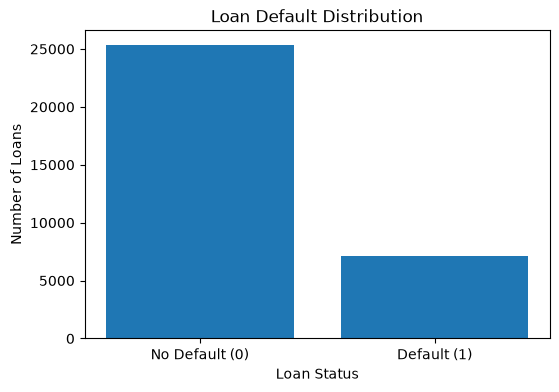

In [3]:
status_counts = df["loan_status"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(["No Default (0)", "Default (1)"], status_counts.values)

plt.title("Loan Default Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")

plt.show()

In [4]:
grade_default = (
    df.groupby("loan_grade")["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

grade_default["default_rate"] = (
    grade_default["sum"] / grade_default["count"] * 100
)

grade_default = grade_default.sort_values("default_rate", ascending=False)

grade_default

,loan_grade,count,sum,default_rate
6,G,64,63,98.437500
5,F,241,170,70.539419
4,E,963,621,64.485981
3,D,3620,2138,59.060773
2,C,6438,1336,20.751786
1,B,10387,1695,16.318475
0,A,10703,1066,9.959824


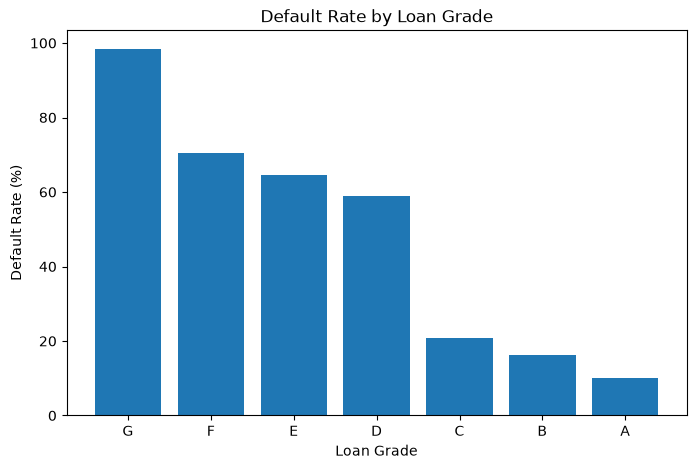

In [5]:
plt.figure(figsize=(8, 5))

plt.bar(
    grade_default["loan_grade"],
    grade_default["default_rate"]
)

plt.title("Default Rate by Loan Grade")
plt.xlabel("Loan Grade")
plt.ylabel("Default Rate (%)")

plt.show()

In [6]:
intent_default = (
    df.groupby("loan_intent")["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

intent_default["default_rate"] = (
    intent_default["sum"] / intent_default["count"] * 100
)

intent_default = intent_default.sort_values(
    "default_rate",
    ascending=False
)

intent_default

,loan_intent,count,sum,default_rate
0,DEBTCONSOLIDATION,5189,1488,28.676045
3,MEDICAL,6042,1617,26.762661
2,HOMEIMPROVEMENT,3594,940,26.154702
4,PERSONAL,5498,1094,19.898145
1,EDUCATION,6411,1106,17.251599
5,VENTURE,5682,844,14.853925


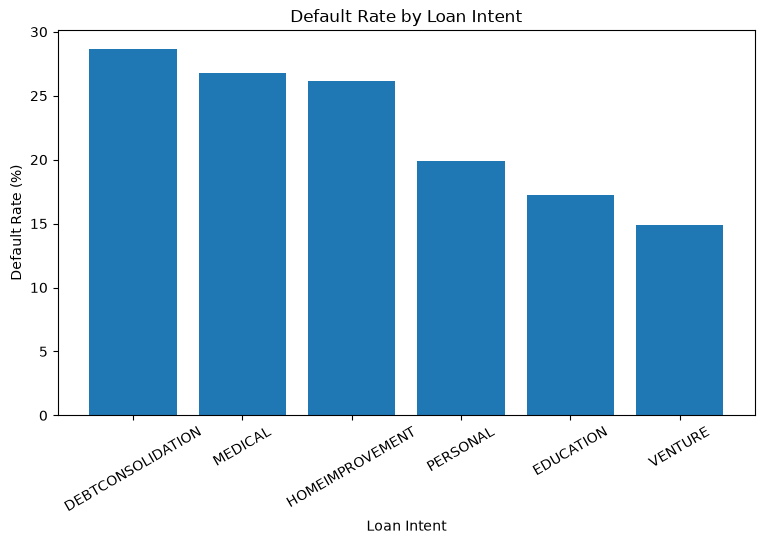

In [7]:
plt.figure(figsize=(9, 5))

plt.bar(
    intent_default["loan_intent"],
    intent_default["default_rate"]
)

plt.title("Default Rate by Loan Intent")
plt.xlabel("Loan Intent")
plt.ylabel("Default Rate (%)")

plt.xticks(rotation=30)

plt.show()

In [8]:
ownership_default = (
    df.groupby("person_home_ownership")["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

ownership_default["default_rate"] = (
    ownership_default["sum"] / ownership_default["count"] * 100
)

ownership_default = ownership_default.sort_values(
    "default_rate",
    ascending=False
)

ownership_default

,person_home_ownership,count,sum,default_rate
3,RENT,16378,5177,31.609476
1,OTHER,106,33,31.132075
0,MORTGAGE,13369,1687,12.618745
2,OWN,2563,192,7.491221


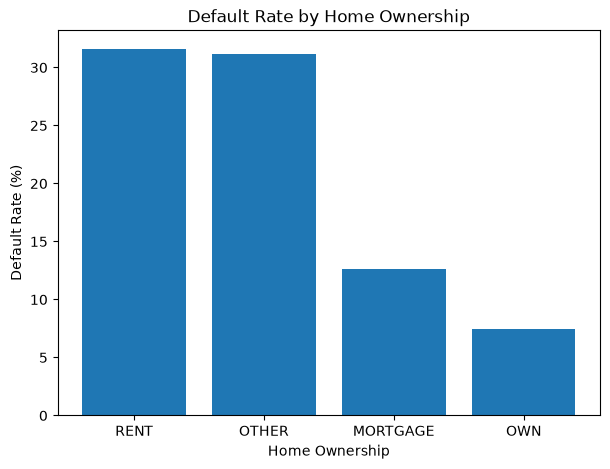

In [9]:
plt.figure(figsize=(7, 5))

plt.bar(
    ownership_default["person_home_ownership"],
    ownership_default["default_rate"]
)

plt.title("Default Rate by Home Ownership")
plt.xlabel("Home Ownership")
plt.ylabel("Default Rate (%)")

plt.show()

In [10]:
previous_default = (
    df.groupby("cb_person_default_on_file")["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

previous_default["default_rate"] = (
    previous_default["sum"] / previous_default["count"] * 100
)

previous_default = previous_default.sort_values(
    "default_rate",
    ascending=False
)

previous_default

,cb_person_default_on_file,count,sum,default_rate
1,Y,5730,2170,37.870855
0,N,26686,4919,18.432886


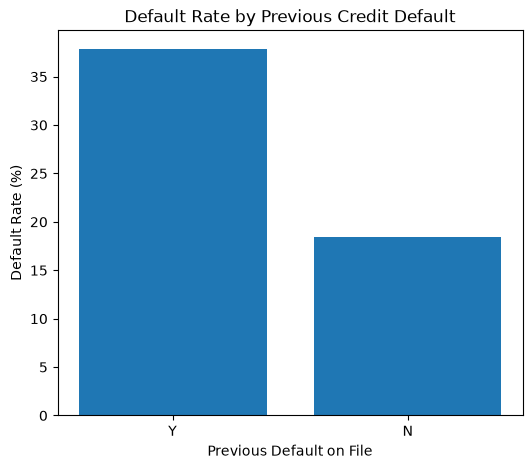

In [11]:
plt.figure(figsize=(6, 5))

plt.bar(
    previous_default["cb_person_default_on_file"],
    previous_default["default_rate"]
)

plt.title("Default Rate by Previous Credit Default")
plt.xlabel("Previous Default on File")
plt.ylabel("Default Rate (%)")

plt.show()

In [12]:
df["income_group"] = pd.cut(
    df["person_income"],
    bins=[0, 30000, 50000, 75000, 100000, float("inf")],
    labels=["Below 30K", "30K-49K", "50K-74K", "75K-99K", "100K+"]
)

income_default = (
    df.groupby("income_group", observed=False)["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

income_default["default_rate"] = (
    income_default["sum"] / income_default["count"] * 100
)

income_default

,income_group,count,sum,default_rate
0,Below 30K,4486,2045,45.586268
1,30K-49K,9513,2441,25.659624
2,50K-74K,9585,1691,17.642149
3,75K-99K,4641,512,11.032105
4,100K+,4191,400,9.544262


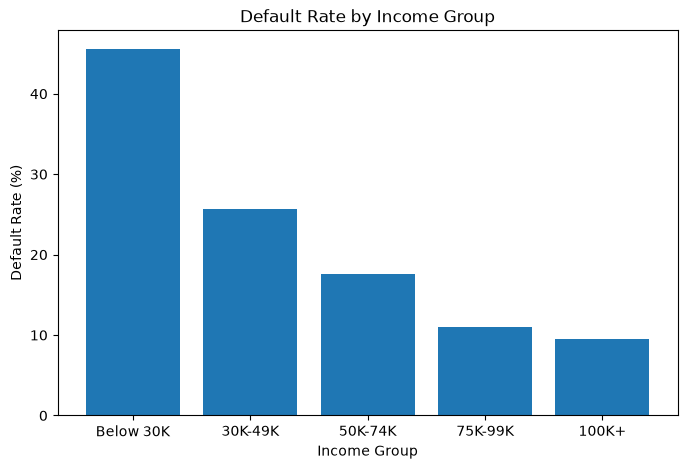

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    income_default["income_group"].astype(str),
    income_default["default_rate"]
)

plt.title("Default Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Default Rate (%)")

plt.show()

In [14]:
df["loan_amount_group"] = pd.cut(
    df["loan_amnt"],
    bins=[0, 5000, 10000, 15000, 20000, float("inf")],
    labels=["Below 5K", "5K-9.9K", "10K-14.9K", "15K-19.9K", "20K+"]
)

loan_amount_default = (
    df.groupby("loan_amount_group", observed=False)["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

loan_amount_default["default_rate"] = (
    loan_amount_default["sum"] /
    loan_amount_default["count"] * 100
)

loan_amount_default

,loan_amount_group,count,sum,default_rate
0,Below 5K,9430,1930,20.466596
1,5K-9.9K,11983,2162,18.042226
2,10K-14.9K,6091,1406,23.083238
3,15K-19.9K,2783,848,30.470715
4,20K+,2129,743,34.899014


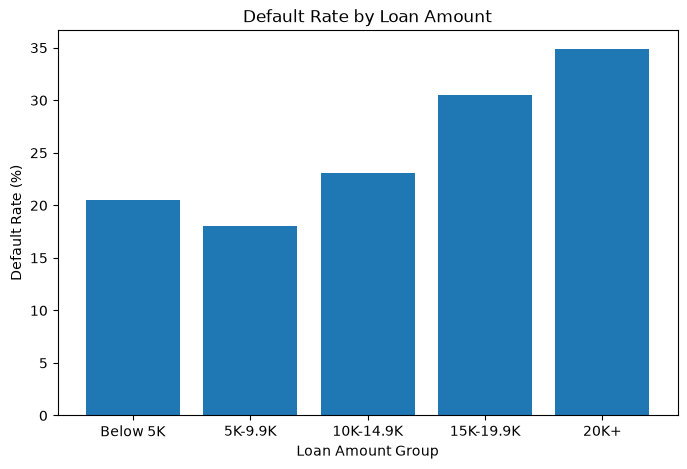

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    loan_amount_default["loan_amount_group"].astype(str),
    loan_amount_default["default_rate"]
)

plt.title("Default Rate by Loan Amount")
plt.xlabel("Loan Amount Group")
plt.ylabel("Default Rate (%)")

plt.show()

In [16]:
df["interest_rate_group"] = pd.cut(
    df["loan_int_rate"],
    bins=[0, 8, 12, 16, 20, float("inf")],
    labels=["Below 8%", "8%-11.99%", "12%-15.99%", "16%-19.99%", "20%+"]
)

interest_default = (
    df.dropna(subset=["loan_int_rate"])
      .groupby("interest_rate_group", observed=False)["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

interest_default["default_rate"] = (
    interest_default["sum"] /
    interest_default["count"] * 100
)

interest_default

,interest_rate_group,count,sum,default_rate
0,Below 8%,7906,737,9.322034
1,8%-11.99%,10299,1633,15.855908
2,12%-15.99%,9344,2963,31.710188
3,16%-19.99%,1698,1052,61.955241
4,20%+,74,63,85.135135


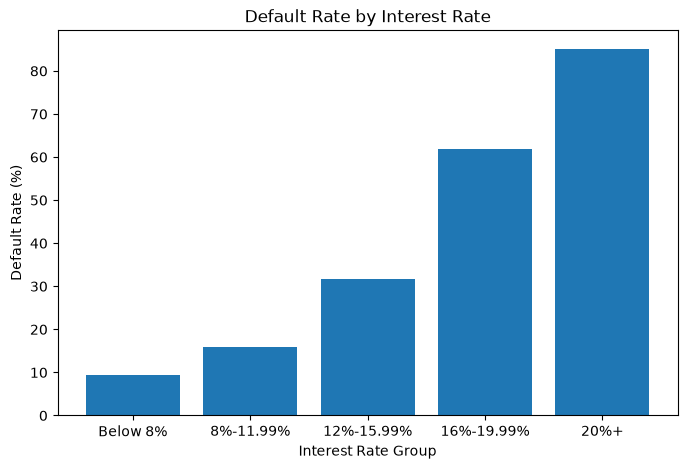

In [17]:
plt.figure(figsize=(8, 5))

plt.bar(
    interest_default["interest_rate_group"].astype(str),
    interest_default["default_rate"]
)

plt.title("Default Rate by Interest Rate")
plt.xlabel("Interest Rate Group")
plt.ylabel("Default Rate (%)")

plt.show()

In [18]:
df["loan_income_group"] = pd.cut(
    df["loan_percent_income"],
    bins=[0, 0.10, 0.20, 0.30, 0.40, float("inf")],
    labels=["Below 10%", "10%-19%", "20%-29%", "30%-39%", "40%+"]
)

loan_income_default = (
    df.groupby("loan_income_group", observed=False)["loan_status"]
      .agg(["count", "sum"])
      .reset_index()
)

loan_income_default["default_rate"] = (
    loan_income_default["sum"] /
    loan_income_default["count"] * 100
)

loan_income_default

,loan_income_group,count,sum,default_rate
0,Below 10%,10421,1226,11.764706
1,10%-19%,11999,1815,15.126261
2,20%-29%,6168,1358,22.016861
3,30%-39%,2700,1860,68.888889
4,40%+,1119,830,74.173369


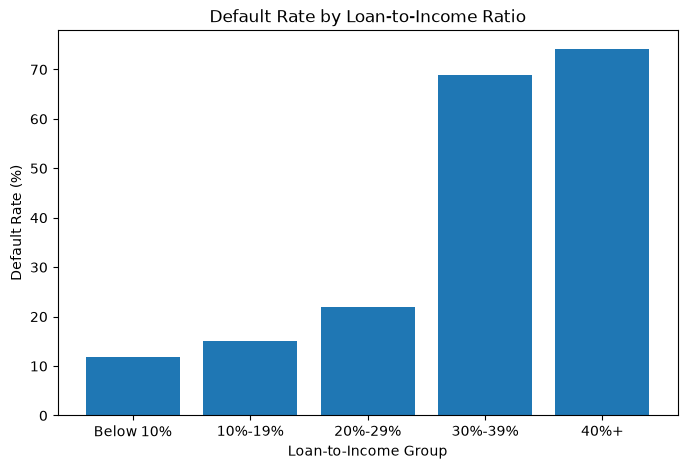

In [19]:
plt.figure(figsize=(8, 5))

plt.bar(
    loan_income_default["loan_income_group"].astype(str),
    loan_income_default["default_rate"]
)

plt.title("Default Rate by Loan-to-Income Ratio")
plt.xlabel("Loan-to-Income Group")
plt.ylabel("Default Rate (%)")

plt.show()

In [20]:
numeric_cols = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "loan_percent_income",
    "cb_person_cred_hist_length",
    "loan_status"
]

correlation = df[numeric_cols].corr()["loan_status"].sort_values(ascending=False)

correlation

loan_status                   1.000000
loan_percent_income           0.379697
loan_int_rate                 0.335853
loan_amnt                     0.105736
cb_person_cred_hist_length   -0.016498
person_age                   -0.021808
person_emp_length            -0.086327
person_income                -0.145005
Name: loan_status, dtype: float64

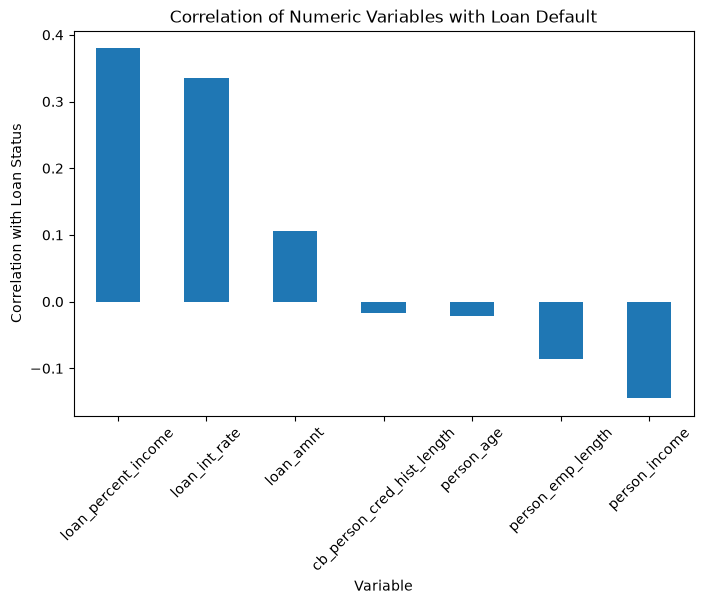

In [21]:
plt.figure(figsize=(8, 5))

correlation.drop("loan_status").plot(kind="bar")

plt.title("Correlation of Numeric Variables with Loan Default")
plt.xlabel("Variable")
plt.ylabel("Correlation with Loan Status")

plt.xticks(rotation=45)

plt.show()